In [20]:
import pandas as pd 
import matplotlib.pyplot as plt

df = pd.read_csv("netflix_cleaned.csv")
df.shape

(8786, 16)

In [21]:
df["country"].value_counts().head(10)

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Unknown            287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

In [22]:
df["country"].str.contains(",").sum()


np.int64(0)

In [23]:
df["country"].nunique

<bound method IndexOpsMixin.nunique of 0       United States
1              France
2       United States
3              Brazil
4       United States
            ...      
8781           Turkey
8782    United States
8783         Pakistan
8784         Pakistan
8785         Pakistan
Name: country, Length: 8786, dtype: object>

In [24]:
print(df["country"].isnull().sum())
print((df["country"].str.strip() == "").sum())
print((df["country"] != df["country"].str.strip()).sum())

0
0
0


In [25]:
sorted(df["country"].unique())

['Argentina',
 'Australia',
 'Austria',
 'Bangladesh',
 'Belarus',
 'Belgium',
 'Brazil',
 'Bulgaria',
 'Cambodia',
 'Cameroon',
 'Canada',
 'Chile',
 'China',
 'Colombia',
 'Croatia',
 'Cyprus',
 'Czech Republic',
 'Denmark',
 'Egypt',
 'Finland',
 'France',
 'Georgia',
 'Germany',
 'Ghana',
 'Greece',
 'Guatemala',
 'Hong Kong',
 'Hungary',
 'Iceland',
 'India',
 'Indonesia',
 'Iran',
 'Ireland',
 'Israel',
 'Italy',
 'Jamaica',
 'Japan',
 'Jordan',
 'Kenya',
 'Kuwait',
 'Lebanon',
 'Luxembourg',
 'Malaysia',
 'Mauritius',
 'Mexico',
 'Mozambique',
 'Namibia',
 'Netherlands',
 'New Zealand',
 'Nigeria',
 'Norway',
 'Pakistan',
 'Paraguay',
 'Peru',
 'Philippines',
 'Poland',
 'Portugal',
 'Puerto Rico',
 'Romania',
 'Russia',
 'Saudi Arabia',
 'Senegal',
 'Serbia',
 'Singapore',
 'Slovenia',
 'Somalia',
 'South Africa',
 'South Korea',
 'Soviet Union',
 'Spain',
 'Sweden',
 'Switzerland',
 'Syria',
 'Taiwan',
 'Thailand',
 'Turkey',
 'Ukraine',
 'United Arab Emirates',
 'United Kingd

In [26]:
df_country = df[df["country"] != "Unknown"].copy()
df_country.shape

(8499, 16)

In [27]:
country_counts = df_country["country"].value_counts()
country_counts.head(10)

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64

In [28]:
print(country_counts.sum() == len(df_country))
print(len(country_counts))

True
85


In [29]:
top10 = country_counts.head(10)
top10

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64

In [30]:
top10_percent = (top10 / len(df_country) * 100).round(2)
top10_percent


country
United States     38.12
India             12.42
United Kingdom     7.51
Pakistan           4.94
Canada             3.19
Japan              3.05
South Korea        2.52
France             2.51
Spain              2.14
Mexico             1.62
Name: count, dtype: float64

In [31]:
ranking = pd.DataFrame({
    "Titles": top10,
    "Share_%": top10_percent
})
ranking.index.name = "Country"
ranking["Rank"] = range(1, 11)
ranking

,Titles,Share_%,Rank
Country,,,
United States,3240,38.12,1
India,1056,12.42,2
United Kingdom,638,7.51,3
Pakistan,420,4.94,4
Canada,271,3.19,5
Japan,259,3.05,6
South Korea,214,2.52,7
France,213,2.51,8
Spain,182,2.14,9


In [32]:
print("Top 3 share:", round(top10_percent.head(3).sum(), 2), "%")
print("Top 10 share:", round(top10_percent.sum(), 2), "%")

Top 3 share: 58.05 %
Top 10 share: 78.02 %


In [33]:
print("Countries with fewer than 10 titles:", (country_counts < 10).sum())
print("Countries with only 1 title:", (country_counts == 1).sum())

Countries with fewer than 10 titles: 42
Countries with only 1 title: 18


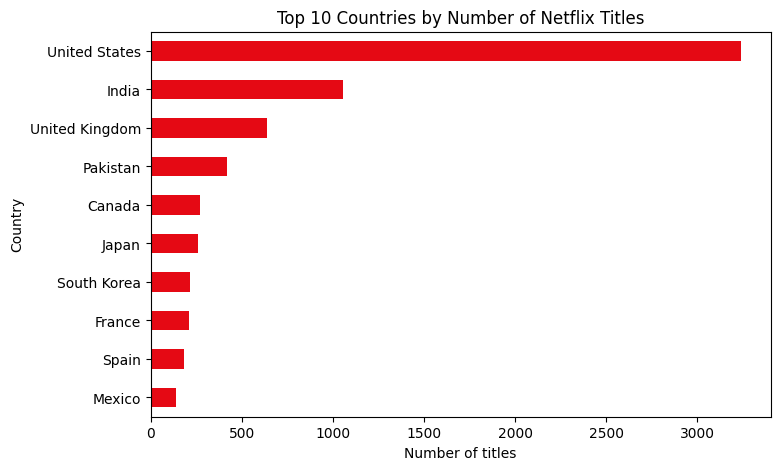

In [34]:
top10.sort_values().plot(kind="barh", color="#E50914", figsize=(8, 5))
plt.title("Top 10 Countries by Number of Netflix Titles")
plt.xlabel("Number of titles")
plt.ylabel("Country")
plt.savefig("top10_countries.png", dpi=150, bbox_inches="tight")
plt.show()

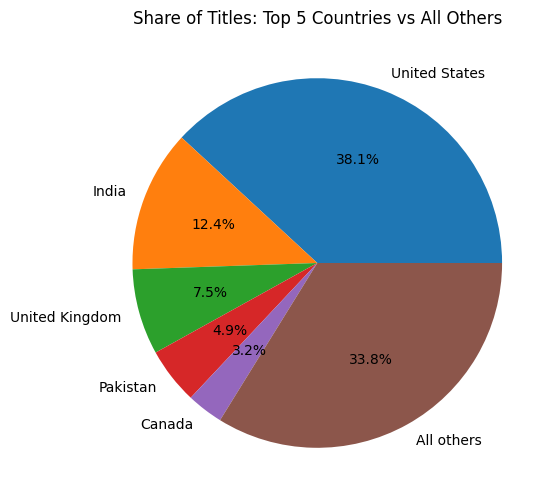

In [35]:
top5 = country_counts.head(5)
other = country_counts.iloc[5:].sum()
share = pd.concat([top5, pd.Series({"All others": other})])

share.plot(kind="pie", autopct="%1.1f%%", figsize=(6, 6))
plt.title("Share of Titles: Top 5 Countries vs All Others")
plt.ylabel("")
plt.savefig("country_share.png", dpi=150, bbox_inches="tight")
plt.show()

In [36]:
ranking

,Titles,Share_%,Rank
Country,,,
United States,3240,38.12,1
India,1056,12.42,2
United Kingdom,638,7.51,3
Pakistan,420,4.94,4
Canada,271,3.19,5
Japan,259,3.05,6
South Korea,214,2.52,7
France,213,2.51,8
Spain,182,2.14,9


In [37]:
ranking.to_csv("country_ranking.csv")

In [38]:
import os
print([f for f in os.listdir() if f.endswith((".png", ".csv", ".ipynb"))])


['01_data_cleaning.ipynb', '02_content_type_analysis.ipynb', '03_country_analysis.ipynb', '04_trend_analysis.ipynb', '05_rating_genre_analysis.ipynb', '06_business_insights_report.ipynb', 'country_ranking.csv', 'country_share.png', 'Dataset.csv', 'netflix_cleaned.csv', 'release_by_type.png', 'release_growth.png', 'release_trend.png', 'top10_countries.png', 'type_distribution.png', 'type_share_by_year.png']


# Country-Wise Content Analysis: Key Findings

## Overview
- Titles analyzed: 8,499 (titles with a known country)
- Excluded: 287 titles (3.27%) with an unknown country
- Countries represented: 85
- Each title lists exactly one country, so no splitting of the country column was needed

## Top 10 Countries by Number of Titles

| Rank | Country | Titles | Share |
|---|---|---|---|
| 1 | United States | 3,240 | 38.12% |
| 2 | India | 1,056 | 12.42% |
| 3 | United Kingdom | 638 | 7.51% |
| 4 | Pakistan | 420 | 4.94% |
| 5 | Canada | 271 | 3.19% |
| 6 | Japan | 259 | 3.05% |
| 7 | South Korea | 214 | 2.52% |
| 8 | France | 213 | 2.51% |
| 9 | Spain | 182 | 2.14% |
| 10 | Mexico | 138 | 1.62% |

## Business Insights
1. **The catalog is heavily concentrated.** The top 10 countries supply 78.02% of titles, and the top 3 supply 58.05%.
2. **The United States dominates.** It holds 38.12% of titles, about 3 times more than India, the second-largest.
3. **India is the clear number 2.** With 1,056 titles it is far ahead of the United Kingdom (638), which shows how important the Indian market is.
4. **There is a long tail.** Of 85 countries, 42 have fewer than 10 titles and 18 have only 1. These markets are thinly covered and could be a growth opportunity.
5. **Asia is well represented.** India, Pakistan, Japan and South Korea all appear in the top 10.

## Caveats
- 287 titles with an unknown country were excluded from the ranking.
- Each title has one country listed, so titles made in several countries are counted under only one.
- The data shows where content comes from, not how many people watch it.

## Charts and Files
- `top10_countries.png`: horizontal bar chart of the top 10
- `country_share.png`: pie chart of the top 5 vs all others
- `country_ranking.csv`: the ranking table

## Recommendation
Netflix could look at growing content from under-represented countries to reach new audiences, while keeping its strong base in the US, India and the UK.
